# 01 — Exploratory Data Analysis
**Project 09:** Global Logistics Multi-Class Intelligence

Load data, explore distributions, check quality.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
plt.style.use('seaborn-v0_8-whitegrid')
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
RAW='data/raw'; CHARTS='charts/eda'
os.makedirs(CHARTS, exist_ok=True)
print(f'CWD: {os.getcwd()}')

CWD: /home/ashutosh/Desktop/NO-AI-USE/ml_projects/09_logistics_multiclass_intelligence


## 1. Load Data

In [2]:
df = pd.read_csv(f'{RAW}/DataCoSupplyChainDataset.csv', encoding='latin-1', low_memory=False)
print(f'Shape: {df.shape}')
df.head(3)

Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


In [3]:
print('Dtypes:'); print(df.dtypes.value_counts())
print(f'\nNulls (top 10):'); print(df.isnull().sum().sort_values(ascending=False).head(10))
print(f'\nDuplicates: {df.duplicated().sum()}')

Dtypes:
object     24
float64    15
int64      14
Name: count, dtype: int64

Nulls (top 10):


Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
Sales per customer                    0
Benefit per order                     0
Delivery Status                       0
Late_delivery_risk                    0
Customer City                         0
dtype: int64



Duplicates: 0


## 2. Target Distribution

Classes: ['Advance shipping', 'Late delivery', 'Shipping canceled', 'Shipping on time']
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


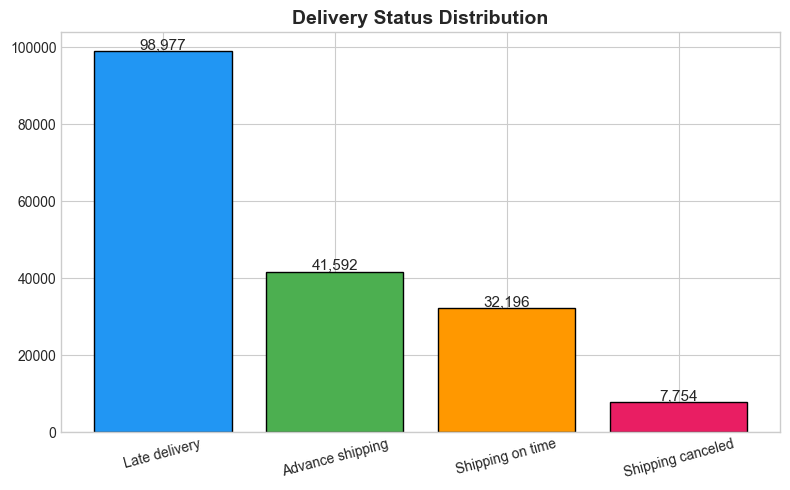

In [4]:
TARGET='Delivery Status'
CLASS_NAMES=sorted(df[TARGET].unique().tolist())
colors=['#2196F3','#4CAF50','#FF9800','#E91E63']
print(f'Classes: {CLASS_NAMES}')
print(df[TARGET].value_counts())

fig,ax=plt.subplots(figsize=(8,5))
counts=df[TARGET].value_counts()
bars=ax.bar(counts.index,counts.values,color=colors,edgecolor='black')
for b,v in zip(bars,counts.values): ax.text(b.get_x()+b.get_width()/2,b.get_height()+500,f'{v:,}',ha='center',fontsize=11)
ax.set_title('Delivery Status Distribution',fontsize=14,fontweight='bold')
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(f'{CHARTS}/01_class_distribution.png',dpi=150,bbox_inches='tight'); plt.show()

## 3. Correlation Heatmap

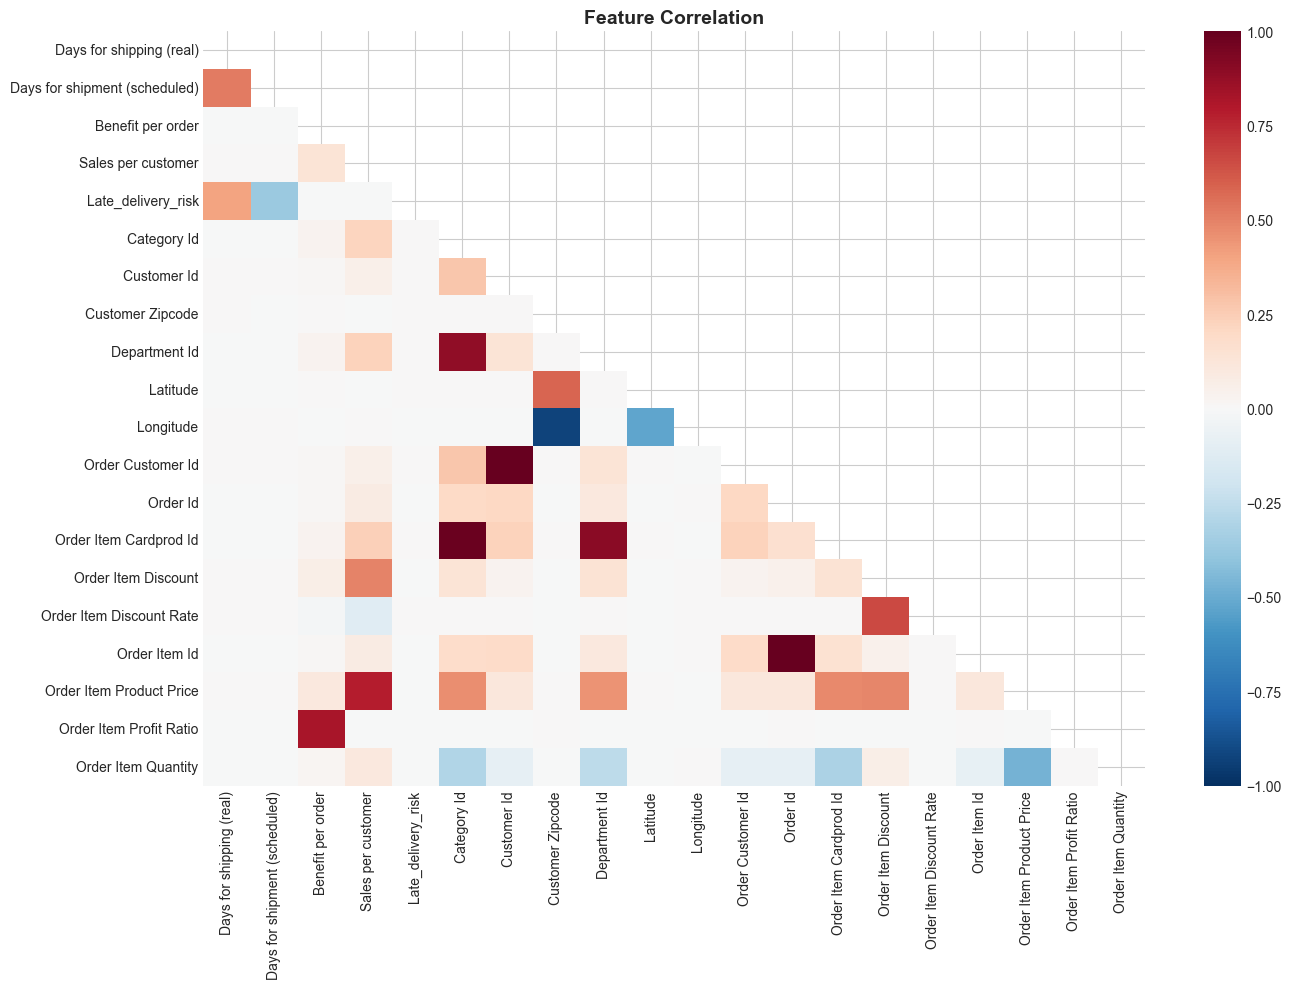

In [5]:
num_cols=df.select_dtypes(include=[np.number]).columns[:20]
fig,ax=plt.subplots(figsize=(14,10))
corr=df[num_cols].corr()
mask=np.triu(np.ones_like(corr,dtype=bool))
sns.heatmap(corr,mask=mask,cmap='RdBu_r',center=0,ax=ax,vmin=-1,vmax=1)
ax.set_title('Feature Correlation',fontsize=14,fontweight='bold')
plt.tight_layout(); plt.savefig(f'{CHARTS}/02_correlation.png',dpi=150,bbox_inches='tight'); plt.show()

## 4. Feature Distributions by Class

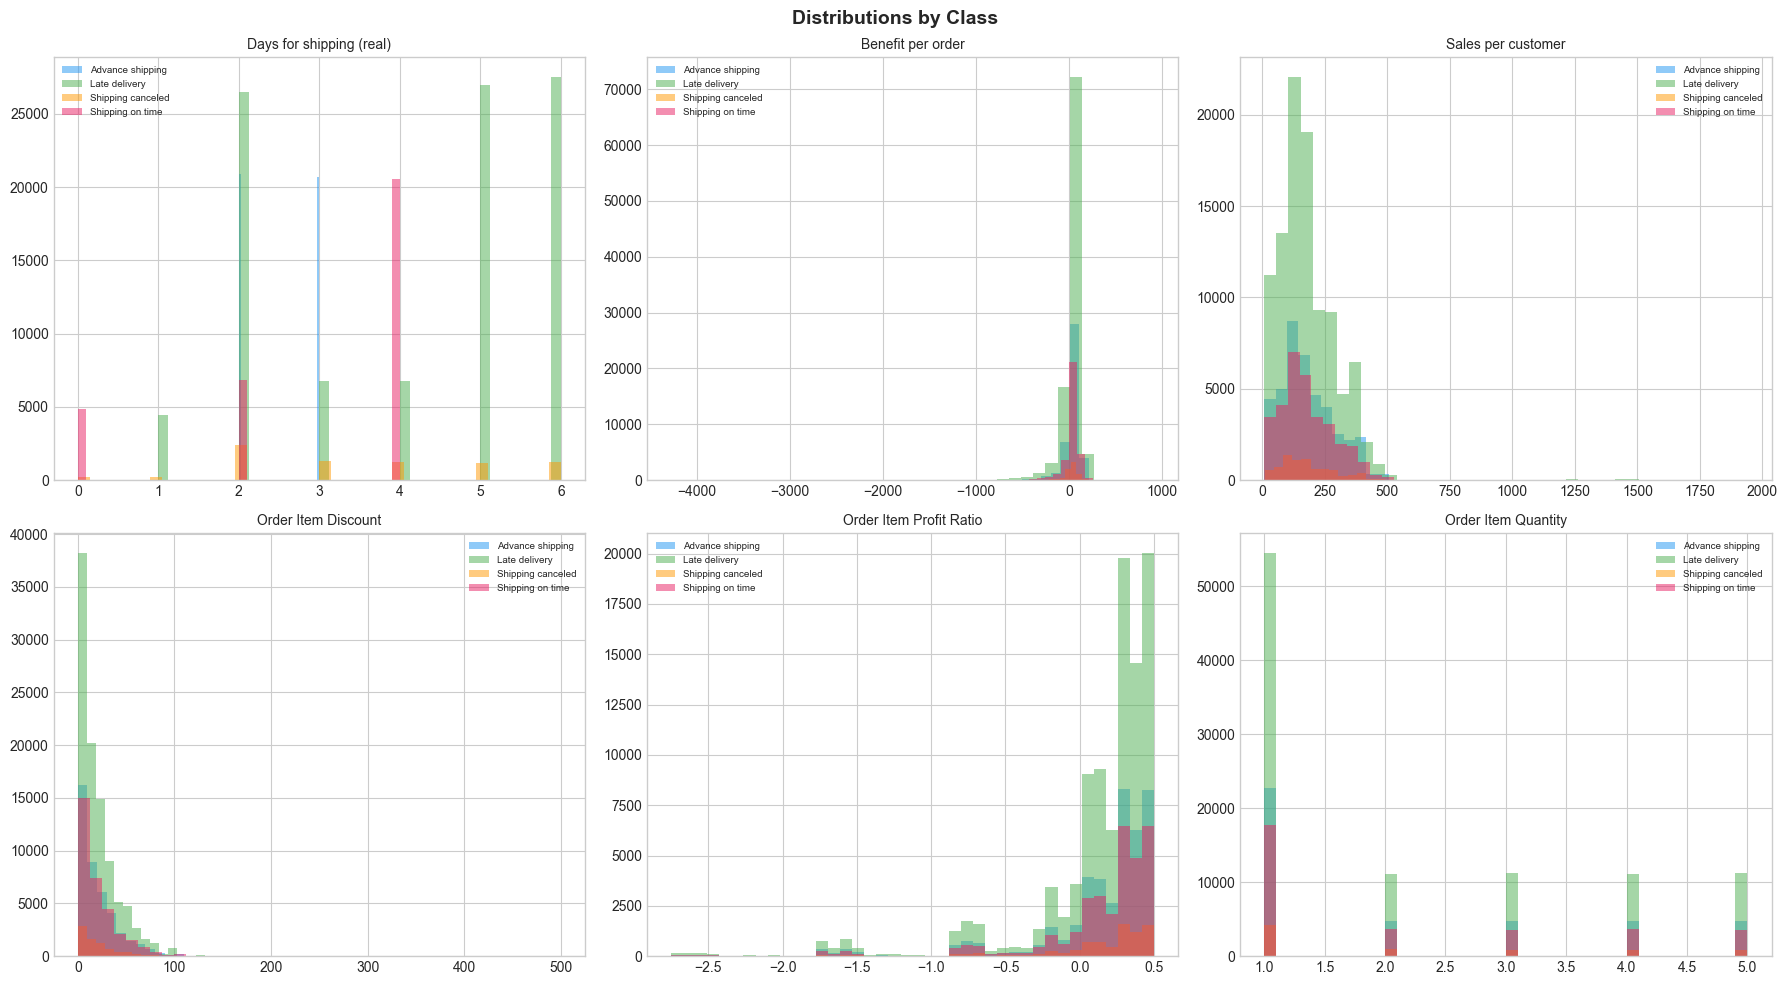

In [6]:
plot_cols=['Days for shipping (real)','Benefit per order','Sales per customer',
           'Order Item Discount','Order Item Profit Ratio','Order Item Quantity']
fig,axes=plt.subplots(2,3,figsize=(18,10)); axes=axes.flatten()
for i,col in enumerate(plot_cols):
    for ci,name in enumerate(CLASS_NAMES):
        axes[i].hist(df[df[TARGET]==name][col].dropna(),bins=40,alpha=0.5,label=name,color=colors[ci])
    axes[i].set_title(col,fontsize=10); axes[i].legend(fontsize=7)
fig.suptitle('Distributions by Class',fontsize=14,fontweight='bold')
plt.tight_layout(); plt.savefig(f'{CHARTS}/03_distributions.png',dpi=150,bbox_inches='tight'); plt.show()

## 5. Categorical Feature Counts

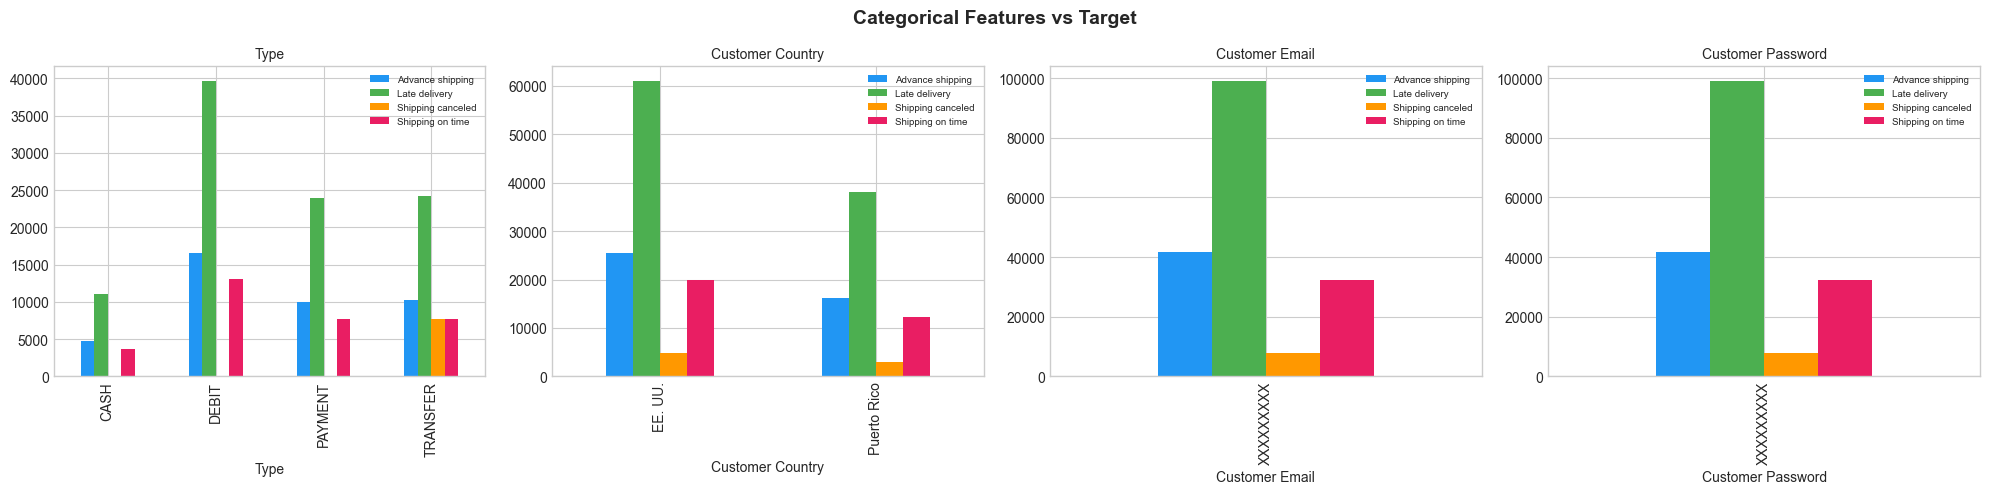

In [7]:
cat_cols_all=df.select_dtypes(include='object').columns.tolist()
cat_to_plot=[c for c in cat_cols_all if df[c].nunique()<=10 and c!=TARGET][:4]
fig,axes=plt.subplots(1,len(cat_to_plot),figsize=(5*len(cat_to_plot),5))
if len(cat_to_plot)==1: axes=[axes]
for i,col in enumerate(cat_to_plot):
    df.groupby([col,TARGET]).size().unstack().plot.bar(ax=axes[i],color=colors)
    axes[i].set_title(col,fontsize=10); axes[i].legend(fontsize=7)
fig.suptitle('Categorical Features vs Target',fontsize=14,fontweight='bold')
plt.tight_layout(); plt.savefig(f'{CHARTS}/04_categorical.png',dpi=150,bbox_inches='tight'); plt.show()

In [8]:
print('\nEDA complete. Charts saved to charts/eda/')
print(f'Dataset: {df.shape[0]:,} rows x {df.shape[1]} cols')
print(f'Target classes: {CLASS_NAMES}')


EDA complete. Charts saved to charts/eda/
Dataset: 180,519 rows x 53 cols
Target classes: ['Advance shipping', 'Late delivery', 'Shipping canceled', 'Shipping on time']
